# TRABAJO PRACTICO INTEGRADOR - SEGUNDO PARCIAL
#### INTEGRANTES:
- Bianciotto Sofia - 1241171
- Cebreiros Juana - 1238673
- Lacava Giuliana - 1239334
- Lazaro Martina - 1238503
##### TEMA: Utilizaremos un dataset de una veterinaria, con el objetivo de predecir un diagnostico segun las variables dadas.

### PARTE 1 - CARGA DE DATOS

HACER:
- borrar fechas y patient id
- transformar las edades a numericas
- imputar los nulos de las columnas que quedan

In [126]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

In [127]:
df = pd.read_csv("Vet_Clinical_Dataset.csv")
print("el Dataset fue cargado exitosamente. Tiene las siguientes dimensiones:")
df.shape

el Dataset fue cargado exitosamente. Tiene las siguientes dimensiones:


(2000, 15)

### PARTE 2 - EDA INICIAL - PREPARACIÓN Y LIMPIEZA DE DATOS

En los siguientes cuadros de codigo, revisaremos el dataset y los datos del mismo, verificando si hay valores nulos, duplicados, faltantes. Luego analizaremos que hacer frente a cada problema encontrado. 

In [128]:
df.columns

Index(['Patient ID', 'ownership_status', 'intake date', 'booking date',
       'species', 'breed', 'age', 'sex', 'weight', 'temperature', 'heart rate',
       'intake location', 'Body condition score', 'wood lamp fungal',
       'definitive diagnosis'],
      dtype='str')

Que informacion nos da cada columna:
- Patitient ID: codigo de identificacion unico para cada caso. 
- ownership_status: origen del animal (owned - recued - lost_rescued)
- intake date: fecha en que el animal fue llevado a la consulta para la evaluacion clinica
- booking date: fecha de una consulta con reserva previa
- intake location: area geografica (en la ciudad de Makati)
- species: tipo de animal
- breed: clasificacion de raza
- age: edad del paciente
- sex: genero del paciente
- weight: peso del paciente (en kg)
- temperature: temperatura corporal al ingreso a la consulta (en grados Celsius)
- heart rate: latidos por minuto
- body condition score: condicion corporal en una escala del 1 (escualido) al 9 (obesidad)
- wood lamp fungal: test para detectar infecciones (positive - negative)
- definitive diagnosis: el diagnostico final dictado por el veterinario de turno

In [129]:
df.head(3) #primero 3 registros del dataset


,Patient ID,ownership_status,intake date,booking date,species,breed,age,sex,weight,temperature,heart rate,intake location,Body condition score,wood lamp fungal,definitive diagnosis
0,25021825,rescued,2/28/2025,NaN,canine,Aspin,4 years,male,6.7,39.1,114.0,"East Rembo, Makati City",4.0,Negative,Bacterial Dermatitis and Bacterial Otitis
1,23110410,owned,NaN,11/13/2023,canine,Shih Tzu,9 years,male,9.7,39.1,NaN,NaN,4.0,Negative,Atopic Dermatitis
2,23124507,owned,NaN,12/2/2023,canine,Golden Retriever,12 weeks,male,11.7,39.1,NaN,NaN,3.0,Negative,Bacterial Dermatitis and Bacterial Otitis


In [130]:
df.tail(3) #ultimos 3 registros del dataset

,Patient ID,ownership_status,intake date,booking date,species,breed,age,sex,weight,temperature,heart rate,intake location,Body condition score,wood lamp fungal,definitive diagnosis
1997,24124383,rescued,12/18/2024,NaN,canine,Aspin,11 weeks,male,4.0,39.2,NaN,"Urdaneta, Makati City",4.0,Positive,Ringworm
1998,24127367,rescued,12/19/2024,NaN,feline,Puspin,10 years,female,5.0,38.1,196.0,"San Lorenzo, Makati City",7.0,Negative,Bacterial Dermatitis and Bacterial Otitis
1999,24034062,rescued,3/15/2024,NaN,feline,Siamese,12 weeks,female,2.0,38.3,NaN,"Bel-Air, Makati City",7.0,Negative,Ear Mites and Yeast Otitis


In [131]:
df.sample(5) #5 registros aleatorios del datset

,Patient ID,ownership_status,intake date,booking date,species,breed,age,sex,weight,temperature,heart rate,intake location,Body condition score,wood lamp fungal,definitive diagnosis
97,24114340,owned,NaN,11/4/2024,canine,Shih Tzu,9 months,female,6.7,39.1,NaN,NaN,6.0,Negative,Yeast Dermatitis and Yeast Otitis
1533,25083085,lost_rescued,2025-08-07,NaN,canine,French Bulldog,2 years,male,12.2,39.0,104.0,"South Cembo, Makati City",3.0,Negative,Bacterial Dermatitis and Bacterial Otitis
634,23120660,owned,NaN,12/7/2023,feline,Siamese,7 months,male,3.4,38.5,NaN,NaN,5.0,Negative,Bacterial Dermatitis
936,25020846,owned,NaN,2/13/2025,canine,French Bulldog,6 months,female,7.9,39.2,NaN,NaN,3.0,Negative,Ear Mites
151,24058690,owned,NaN,5/27/2024,canine,Golden Retriever,7 months,male,19.6,38.9,NaN,NaN,5.0,Positive,Ringworm and Yeast Otitis


In [132]:
df.info() #panorama general del dataset. cantidad de filas, columnas, nombres de las columnas, cantidad de valores no nulos por columna y tipo de dato de cada columna.

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 15 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Patient ID            2000 non-null   int64  
 1   ownership_status      2000 non-null   str    
 2   intake date           866 non-null    str    
 3   booking date          1134 non-null   str    
 4   species               2000 non-null   str    
 5   breed                 2000 non-null   str    
 6   age                   2000 non-null   str    
 7   sex                   2000 non-null   str    
 8   weight                2000 non-null   float64
 9   temperature           2000 non-null   float64
 10  heart rate            1689 non-null   float64
 11  intake location       866 non-null    str    
 12  Body condition score  1942 non-null   float64
 13  wood lamp fungal      2000 non-null   str    
 14  definitive diagnosis  2000 non-null   str    
dtypes: float64(4), int64(1), str(10)

podemos observar que el datset contiene 2000 filas y 15 columnas, de las cuales 10 no tienen ningun valor nulo. "intake date" - "booking date" - "heart rate" - "intake location" - "body condition score" tienen valores nulos. 

In [133]:
df.describe() #resmen estadistico de las variables numericas

,Patient ID,weight,temperature,heart rate,Body condition score
count,2.000000e+03,2000.000000,2000.000000,1689.000000,1942.000000
mean,2.404418e+07,7.652150,38.711250,129.512729,4.845520
std,8.212429e+05,7.340566,0.294859,41.831217,1.453319
min,2.301009e+07,0.700000,38.000000,66.000000,3.000000
25%,2.309690e+07,3.100000,38.500000,96.000000,3.000000
50%,2.406290e+07,4.500000,38.700000,115.000000,5.000000
75%,2.503390e+07,9.700000,39.000000,165.000000,6.000000
max,2.512987e+07,35.800000,39.300000,230.000000,7.000000


- count: cantidad de valores no nulos
- mean: promedio
- std: desvio estandar
- min: valor minimo 
- 25% - 75%: primer y tercer cuartil
- 50%: mediana
- max: valor maximo

observaciones:
- "heart rate" y "body condition score" tiene valores nulos 
- este no es un analisis significativo para la variable Patient ID, ya que es una variable unica de cada paciente. Serviria mas analizarla como "object". (ver de hacer una transformacion a object)
- en "weight" y "heart rate" el promedio se encuentra alejado del valor de la media, tienen un desvio estandar elevado, por lo que los datos estan dispersos. Puede significar la presencia de algun outlier.

In [134]:
df.describe(include="object") #ahora aplicado a las variables categoricas 

C:\Users\lacav\AppData\Local\Temp\ipykernel_23768\2804790000.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include="object") #ahora aplicado a las variables categoricas


,ownership_status,intake date,booking date,species,breed,age,sex,intake location,wood lamp fungal,definitive diagnosis
count,2000,866,1134,2000,2000,2000,2000,866,2000,2000
unique,3,586,678,2,13,26,2,16,2,13
top,owned,9/24/2024,2023-05-08,canine,Aspin,11 months,female,"South Cembo, Makati City",Negative,Ear Mites and Yeast Otitis
freq,1134,4,6,1199,484,131,1008,69,1683,181


- count: valores no nulos
- unique: cantidad de valores unicos
- top: valor mas frecuete
- freq: frecuencia del valor mas frecuente

observaciones: 
- sobre "ownership status":     
        - el valor mas repetido es "owned" apareciendo 1134 veces de 2000 registros totales, lo que significa que al menos de la mitad de los animmales atendidos tenian dueño. 
- sobre "intake date":
       - hay varios valores faltantes, de 2000 ingresos, solo se registraron 866 en esta categoria. las fechas de ingreso estan muy distribuidas, no existe una en particular que acumule un gran porcentaje de animales ingresados. 
- sobre "booking date":
        - lo mismo que para la variable anterior, muchos datos faltantes 
- sobre "species":
        - hay solamente 2 tipos de especies, siendo apenas mas de la mitad "canine"
- sobre "breed":
        - hay 13 razas diferentes, siendo "Aspin" la as frecuente, representando el 24,2% de los registros
- sobre "age":
        - de 26 edades registradas, ninguna representa una gran mayoria de los datos. 
- sobre "sex":
        - el sexo femenino esta muy levemente mas repetido que el sexo masculino (los dos unicos valores posibles)
- sobre "intake location":
        - ninguna de las 16 ubicaciones esta mucho mas repetida que el resto. hay que considerar que hay mas de la mitad de valores faltantes
- sobre "wood lamp fungal":
        - la mayoria de los resultados dio negativo (el 84,15%). solo el 15,85% dio positivo. todos los animales se fueron sometidos  este test.
- sobre "definitive diagnosis":
        - hubo 13 diagnosticos distintos, el mas repetido "ear mites and yeast otitis", sin predominar ampliamente por sobre el resto

In [135]:
df.describe(include="all") #esta es la forma de incluir lo de ambas tablas anteriores en una sola

,Patient ID,ownership_status,intake date,booking date,species,breed,age,sex,weight,temperature,heart rate,intake location,Body condition score,wood lamp fungal,definitive diagnosis
count,2.000000e+03,2000,866,1134,2000,2000,2000,2000,2000.000000,2000.000000,1689.000000,866,1942.000000,2000,2000
unique,NaN,3,586,678,2,13,26,2,NaN,NaN,NaN,16,NaN,2,13
top,NaN,owned,9/24/2024,2023-05-08,canine,Aspin,11 months,female,NaN,NaN,NaN,"South Cembo, Makati City",NaN,Negative,Ear Mites and Yeast Otitis
freq,NaN,1134,4,6,1199,484,131,1008,NaN,NaN,NaN,69,NaN,1683,181
mean,2.404418e+07,NaN,NaN,NaN,NaN,NaN,NaN,NaN,7.652150,38.711250,129.512729,NaN,4.845520,NaN,NaN
std,8.212429e+05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,7.340566,0.294859,41.831217,NaN,1.453319,NaN,NaN
min,2.301009e+07,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.700000,38.000000,66.000000,NaN,3.000000,NaN,NaN
25%,2.309690e+07,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.100000,38.500000,96.000000,NaN,3.000000,NaN,NaN
50%,2.406290e+07,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.500000,38.700000,115.000000,NaN,5.000000,NaN,NaN
75%,2.503390e+07,NaN,NaN,NaN,NaN,NaN,NaN,NaN,9.700000,39.000000,165.000000,NaN,6.000000,NaN,NaN


completar la info de pq decidimos eliminarlas

In [136]:
df = df.drop(columns=["Patient ID" , "intake date" , "booking date"])

In [137]:
df.columns #confirmamos que hayan sido eliminadas

Index(['ownership_status', 'species', 'breed', 'age', 'sex', 'weight',
       'temperature', 'heart rate', 'intake location', 'Body condition score',
       'wood lamp fungal', 'definitive diagnosis'],
      dtype='str')

tranformaremos la variable age para poder trabajar mejor con ella -- completar explicacion

In [138]:
df["age"].unique() #observamos los posobles valores y el tipo (str). la tranformaremos a una variable numerica

<StringArray>
[  '4 years',   '9 years',  '12 weeks',  '12 years',   '3 years',   '6 years',
  '10 years',  '9 months',   '5 years', '11 months',   '1 years',  '5 months',
  '8 months',  '7 months',   '8 weeks',   '7 years',  '11 years',   '9 weeks',
   '2 years',  '6 months', '10 months',  '4 months',   '8 years',  '3 months',
  '11 weeks',  '10 weeks']
Length: 26, dtype: str

In [139]:
#creamos una funcion de apoyo para la transformacion
def convertir_age(edad):
    edad = str(edad).lower().strip()
    if "years" in edad:
        return float(edad.replace("years" , "").strip())
    elif "months" in edad:
        return float(edad.replace("months" , "").strip()) / 12
    elif "weeks" in edad:
        return float(edad.replace("weeks" , "").strip()) / 52
    else:
        return "edad no valida"

aclaracion: ahora las edades estaran todas expresadas en funcion de años, es decir, 6 meses sera 0.5 (años), 11 semanas sera 0.2115538... (años).

In [140]:
df["age"] = df["age"].apply(convertir_age)
df["age"]

0        4.000000
1        9.000000
2        0.230769
3       12.000000
4        3.000000
          ...    
1995     0.750000
1996     7.000000
1997     0.211538
1998    10.000000
1999     0.230769
Name: age, Length: 2000, dtype: float64

In [141]:
df["age"].dtype

dtype('float64')

In [142]:
df.describe() #ahora podemos incluir la variable age en el analisis de las numericas

,age,weight,temperature,heart rate,Body condition score
count,2000.000000,2000.000000,2000.000000,1689.000000,1942.000000
mean,2.729029,7.652150,38.711250,129.512729,4.845520
std,3.436170,7.340566,0.294859,41.831217,1.453319
min,0.153846,0.700000,38.000000,66.000000,3.000000
25%,0.416667,3.100000,38.500000,96.000000,3.000000
50%,0.833333,4.500000,38.700000,115.000000,5.000000
75%,5.000000,9.700000,39.000000,165.000000,6.000000
max,12.000000,35.800000,39.300000,230.000000,7.000000


In [143]:
df["ownership_status"].value_counts()

ownership_status
owned           1134
rescued          684
lost_rescued     182
Name: count, dtype: int64

de 2000 animales: 56,7% tenian dueño - 32,4% fueron rescatados - 9,1% fueron "lost_rescued"

In [144]:
df["breed"].value_counts() #cuantos ingresos de cada raza

breed
Aspin                 484
Puspin                342
Persian               121
Domestic Shorthair    120
Siberian Husky        113
Chihuahua             110
British Shorthair     109
Siamese               109
French Bulldog        109
Shih Tzu              102
Golden Retriever       98
Pomeranian             93
Poodle                 90
Name: count, dtype: int64

In [145]:
df["intake location"].value_counts() #cuantos ingresos por cada ubicacion

intake location
South Cembo, Makati City            69
Palanan, Makati City                64
Pitogo, Makati City                 64
Urdaneta, Makati City               62
Bel-Air, Makati City                56
Guadalupe Nuevo, Makati City        56
East Rembo, Makati City             55
Pembo, Makati City                  54
San Lorenzo, Makati City            53
Guadalupe Viejo, Makati City        53
Makati Central Business District    51
Rizal, Makati City                  49
West Rembo, Makati City             47
Comembo, Makati City                46
Poblacion, Makati City              46
San Antonio, Makati City            41
Name: count, dtype: int64

In [146]:
df.duplicated().sum()

np.int64(0)

no hay ningun registro con exactamente los mismos valores en todas sus columnas.

In [147]:
df.isnull().sum() #nos muestra los valores nulos por columna

ownership_status           0
species                    0
breed                      0
age                        0
sex                        0
weight                     0
temperature                0
heart rate               311
intake location         1134
Body condition score      58
wood lamp fungal           0
definitive diagnosis       0
dtype: int64

Podemos observar:
- "intake date" tiene 1134 valores nulos.
- "booking date" tiene 866 valores nulos.
- "heart rate" tiene 311 valores nulos.
- "intake location" tiene 1134 valores nulos. 
- "body condition score" tiene 58 valores nulos.
- todo el resto de las columnas no tiene valores nulos. 

In [148]:
nulos_porcentaje = df.isnull().sum() / (len(df)) * 100

print(nulos_porcentaje) #nos muestra el porcentaje de datos nulos por columna

ownership_status         0.00
species                  0.00
breed                    0.00
age                      0.00
sex                      0.00
weight                   0.00
temperature              0.00
heart rate              15.55
intake location         56.70
Body condition score     2.90
wood lamp fungal         0.00
definitive diagnosis     0.00
dtype: float64


In [149]:
df[df.isnull().any(axis=1)] #visualizacion de registros con al menos 1 dato faltante

,ownership_status,species,breed,age,sex,weight,temperature,heart rate,intake location,Body condition score,wood lamp fungal,definitive diagnosis
1,owned,canine,Shih Tzu,9.000000,male,9.7,39.1,NaN,NaN,4.0,Negative,Atopic Dermatitis
2,owned,canine,Golden Retriever,0.230769,male,11.7,39.1,NaN,NaN,3.0,Negative,Bacterial Dermatitis and Bacterial Otitis
3,owned,feline,Puspin,12.000000,female,4.1,38.7,NaN,NaN,3.0,Negative,Ear Mites and Yeast Otitis
5,owned,canine,Aspin,6.000000,male,10.3,39.2,NaN,NaN,4.0,Negative,Yeast Dermatitis
6,owned,feline,British Shorthair,10.000000,female,5.6,38.9,NaN,NaN,5.0,Negative,Yeast Otitis
...,...,...,...,...,...,...,...,...,...,...,...,...
1994,lost_rescued,feline,Persian,0.500000,male,2.7,38.9,NaN,Makati Central Business District,6.0,Negative,Bacterial Otitis
1995,owned,canine,Aspin,0.750000,female,13.3,39.0,104.0,NaN,7.0,Negative,Bacterial Dermatitis
1996,rescued,canine,French Bulldog,7.000000,female,22.0,38.9,NaN,Makati Central Business District,5.0,Negative,Atopic Dermatitis
1997,rescued,canine,Aspin,0.211538,male,4.0,39.2,NaN,"Urdaneta, Makati City",4.0,Positive,Ringworm


### imputacion de nulos

ver de separar heart rate para la imputacion segun si es canino o felino

In [150]:
df["heart rate"] = df["heart rate"].fillna(df["heart rate"].median())

In [151]:
df["Body condition score"] = df["Body condition score"].fillna(df["Body condition score"].median())

In [152]:
df["intake location"] = df["intake location"].fillna("Desconocido")

In [153]:
df.head(15) #observamos el dataset sin nulos

,ownership_status,species,breed,age,sex,weight,temperature,heart rate,intake location,Body condition score,wood lamp fungal,definitive diagnosis
0,rescued,canine,Aspin,4.000000,male,6.7,39.1,114.0,"East Rembo, Makati City",4.0,Negative,Bacterial Dermatitis and Bacterial Otitis
1,owned,canine,Shih Tzu,9.000000,male,9.7,39.1,115.0,Desconocido,4.0,Negative,Atopic Dermatitis
2,owned,canine,Golden Retriever,0.230769,male,11.7,39.1,115.0,Desconocido,3.0,Negative,Bacterial Dermatitis and Bacterial Otitis
3,owned,feline,Puspin,12.000000,female,4.1,38.7,115.0,Desconocido,3.0,Negative,Ear Mites and Yeast Otitis
4,rescued,canine,Aspin,3.000000,female,8.1,39.0,79.0,"Comembo, Makati City",3.0,Negative,Ear Mites
5,owned,canine,Aspin,6.000000,male,10.3,39.2,115.0,Desconocido,4.0,Negative,Yeast Dermatitis
6,owned,feline,British Shorthair,10.000000,female,5.6,38.9,115.0,Desconocido,5.0,Negative,Yeast Otitis
7,lost_rescued,canine,Chihuahua,0.750000,male,2.7,38.7,126.0,"Urdaneta, Makati City",5.0,Negative,Ear Mites and Yeast Otitis
8,rescued,feline,Puspin,5.000000,male,4.9,38.2,192.0,"Rizal, Makati City",4.0,Negative,Ear Mites and Yeast Otitis
9,owned,canine,Poodle,0.750000,female,5.7,39.0,115.0,Desconocido,6.0,Negative,Bacterial Otitis


In [154]:
df.isnull().sum()

ownership_status        0
species                 0
breed                   0
age                     0
sex                     0
weight                  0
temperature             0
heart rate              0
intake location         0
Body condition score    0
wood lamp fungal        0
definitive diagnosis    0
dtype: int64

## Análisis Exploratorio de Datos- EDA
En esta sección se realizará un análisis exploratorio del dataset veterinario, con el objetivo de comprender la distribución de las variables, identificar posibles patrones y estudiar las relaciones que podrían resultar relevantes para predecir el diagnóstico definitivo de los pacientes.

In [155]:
#Estadistica descriptivas de las variables numéricas
variables_numericas = [
    'weight',
    'temperature',
    'heart rate',
    'Body condition score',
    'age'
]

df[variables_numericas].describe()

,weight,temperature,heart rate,Body condition score,age
count,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000
mean,7.652150,38.711250,127.256000,4.850000,2.729029
std,7.340566,0.294859,38.798004,1.432315,3.436170
min,0.700000,38.000000,66.000000,3.000000,0.153846
25%,3.100000,38.500000,100.000000,3.000000,0.416667
50%,4.500000,38.700000,115.000000,5.000000,0.833333
75%,9.700000,39.000000,158.000000,6.000000,5.000000
max,35.800000,39.300000,230.000000,7.000000,12.000000


falta el analisis que lo hago una vez que esté la limpieza de datos 

### Distribucion de las variables numéricas relevantes

#### Peso, temperatura y frecuencia cardiaca - Hisotogramas

In [156]:
def plot_histogramas_univariado(df):
    '''
    Grafica los histogramas de peso, temperatura
    y frecuencia cardíaca de los pacientes.
    '''

    # Histogramas
    plt.figure(figsize=(16, 4))

    # Subplot Histograma peso
    plt.subplot(1, 4, 1)
    sns.histplot(data=df, x='weight', bins=15,
                 color='#d96b93', edgecolor='black')
    plt.ylabel('Frecuencia')
    plt.title('Peso')
    plt.xlabel('Peso (kg)')

    # Subplot Histograma temperatura
    plt.subplot(1, 4, 2)
    sns.histplot(data=df, x='temperature', bins=15,
                 color='#d96b93', edgecolor='black')
    plt.ylabel('Frecuencia')
    plt.title('Temperatura')
    plt.xlabel('Temperatura (C°)')

    # Subplot Histograma frecuencia cardíaca
    plt.subplot(1, 4, 3)
    sns.histplot(data=df, x='heart rate', bins=15,
                 color='#d96b93', edgecolor='black')
    plt.ylabel('Frecuencia')
    plt.title('Frecuencia cardíaca')
    plt.xlabel('Frecuencia cardíaca (lpm)')

    # Subplot Histograma edad
    plt.subplot(1, 4, 4)
    sns.histplot(data=df, x='age', bins=15,
                color='#d96b93', edgecolor='black')
    plt.ylabel('Frecuencia')
    plt.title('Edad')
    plt.xlabel('Edad (en años)')

    # Título general centrado
    plt.suptitle(
        'Distribución de las variables numéricas',
        fontsize=14,
        ha='center'
    )

    plt.tight_layout()
    plt.show()

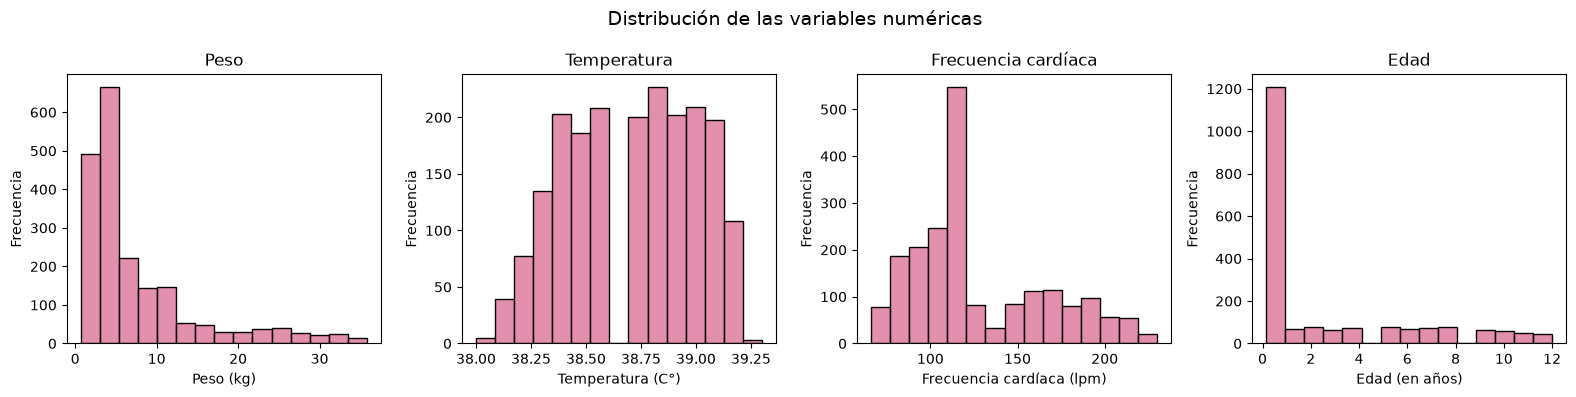

In [157]:
plot_histogramas_univariado(df)


Interpretacion: El peso presenta una distribución asimétrica positiva, con una mayor concentración de pacientes en los valores bajos y una menor frecuencia de pesos elevados.
La temperatura corporal presenta una distribución relativamente concentrada, sin una asimetría muy marcada.
La frecuencia cardíaca muestra diferentes concentraciones de valores, que podrían estar relacionadas con las características fisiológicas de las especies presentes en el dataset.
Por último, la edad presenta una distribución fuertemente asimétrica positiva, con una concentración elevada de pacientes jóvenes y una menor frecuencia de animales de mayor edad.
Estas observaciones permiten identificar patrones que justifican profundizar el análisis mediante comparaciones entre especies y estados de salud

#### Peso, temperatura y frecuencia cardiaca- Boxplots

In [158]:
def plot_boxplots_univariado(df):
    '''
    Grafica los boxplots de peso, temperatura
    y frecuencia cardíaca de los pacientes.
    '''

    # Boxplots
    plt.figure(figsize=(16, 4))

    # Subplot Boxplot peso
    plt.subplot(1, 4, 1)
    sns.boxplot(data=df, x='weight', color='#d96b93')
    plt.xlabel('Peso (kg)')

    # Subplot Boxplot temperatura
    plt.subplot(1, 4, 2)
    sns.boxplot(data=df, x='temperature', color='#d96b93')
    plt.xlabel('Temperatura (C°)')

    # Subplot Boxplot frecuencia cardíaca
    plt.subplot(1, 4, 3)
    sns.boxplot(data=df, x='heart rate', color='#d96b93')
    plt.xlabel('Frecuencia cardíaca (lpm)')
    # Subplot Boxplot edad
    plt.subplot(1, 4, 4)
    sns.boxplot(data=df, x='age', color='#d96b93')
    plt.xlabel('Edad (en años)')

    # Título general centrado
    plt.suptitle(
        'Comparación de la distribución de tres variables numéricas',
        fontsize=14,
        ha='center'
    )

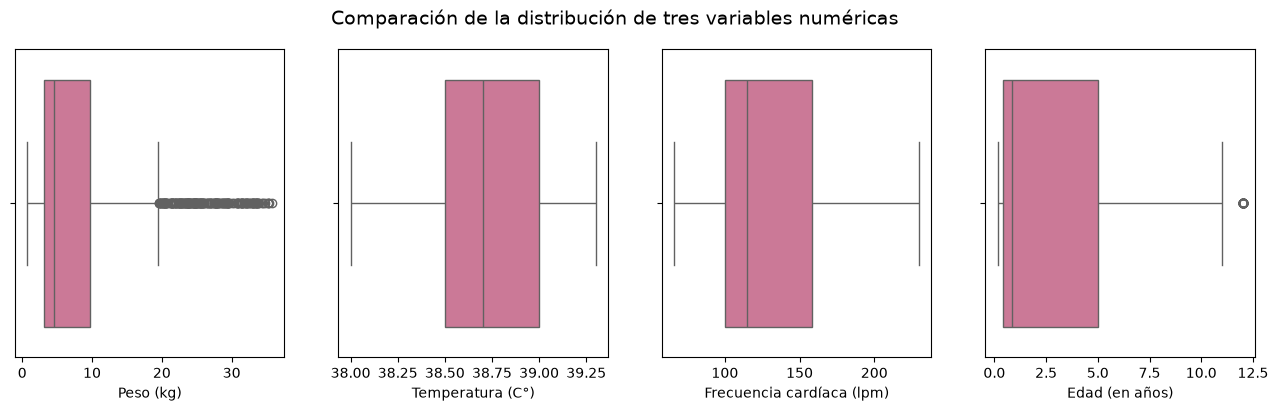

In [159]:
plot_boxplots_univariado(df)

Interpretación: El peso presenta numerosos posibles valores atípicos en los valores elevados. Sin embargo, estos no necesariamente representan errores, ya que podrían corresponder a diferencias de tamaño entre especies y razas.
La temperatura corporal presenta una caja relativamente estrecha y no se observan valores atípicos según el criterio del boxplot.
La frecuencia cardíaca presenta una dispersión considerable dentro de su escala, sin valores atípicos visibles. Sin embargo, este gráfico no permite distinguir claramente las diferentes concentraciones observadas anteriormente en el histograma.
Finalmente, la edad presenta una mediana próxima al primer cuartil, mientras que la caja se extiende hacia edades mayores. También se observa un posible valor atípico cercano a los 12 años, que no necesariamente representa un dato incorrecto.
En conjunto, estos gráficos permiten profundizar el análisis de las distribuciones y comprender mejor la variabilidad de las características de los pacientes.

### Distribucion de la condición corporal
La variable Body condition score representa la puntuación de la condición corporal de los pacientes veterinarios.
A diferencia de las variables analizadas anteriormente, se trata de una variable numérica discreta. Por este motivo, se utilizará un gráfico de barras para visualizar la frecuencia de cada puntuación registrada.

In [160]:
def graficar_barras(df, columna, titulo, hue=None, paso_y=None, paleta=None):
    '''
    Grafica la frecuencia de una variable mediante barras.
    Permite comparar grupos y modificar los intervalos del eje Y.
    '''

    plt.figure(figsize=(8, 4))

    if hue is None:
        sns.countplot(data=df, x=columna,
                      color='#d96b93', edgecolor='black')
    else:
        sns.countplot(data=df, x=columna, hue=hue,
                      palette=paleta, edgecolor='black')

    plt.title(titulo)
    plt.xlabel(columna)
    plt.ylabel('Cantidad de pacientes')

    if paso_y is not None:
        limite_y = int(plt.ylim()[1])
        plt.yticks(range(0, limite_y + paso_y, paso_y))

    if hue is not None:
        plt.legend(title='Estado de salud' if hue == 'estado_salud' else hue)

    plt.show()



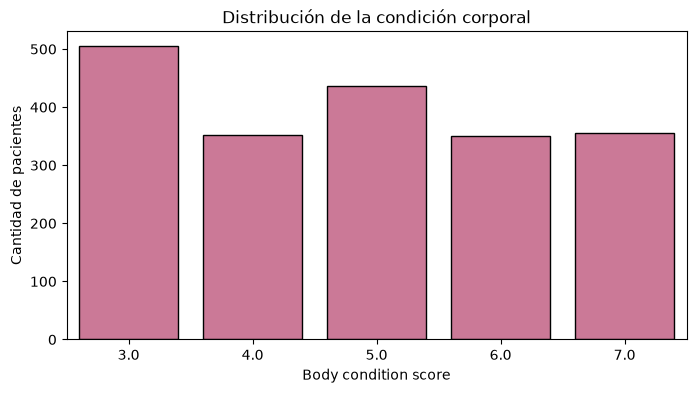

In [161]:
graficar_barras(df, 'Body condition score',
               'Distribución de la condición corporal')

Interpretacion: Se identifica que la puntuación 3 es la más frecuente, seguida por la puntuación 5. Por otro lado, las puntuaciones 4, 6 y 7 presentan frecuencias relativamente similares.
Esta distribución permite conocer las características generales de la condición corporal de los pacientes. Sin embargo, al tratarse de un análisis univariado, no es posible determinar si alguna puntuación está relacionada con un mayor número de enfermedades.

### Distribucion de las variables categoricas 

### Especie y sexo

In [162]:

def plot_categoricas_univariado(df):
    '''
    Grafica la distribución de pacientes
    según especie y sexo.
    '''

    plt.figure(figsize=(12, 4))

    # Subplot de especies
    plt.subplot(1, 2, 1)
    sns.countplot(data=df, x='species',
                  color='#d96b93', edgecolor='black')
    plt.title('Distribución por especie')
    plt.xlabel('Especie')
    plt.ylabel('Cantidad de pacientes')

    # Subplot de sexo
    plt.subplot(1, 2, 2)
    sns.countplot(data=df, x='sex',
                  color='#e8a1be', edgecolor='black')
    plt.title('Distribución por sexo')
    plt.xlabel('Sexo')
    plt.ylabel('Cantidad de pacientes')

    plt.suptitle(
        'Distribución de las variables especie y sexo',
        fontsize=14,
        ha='center'
    )

    plt.tight_layout()
    plt.show()


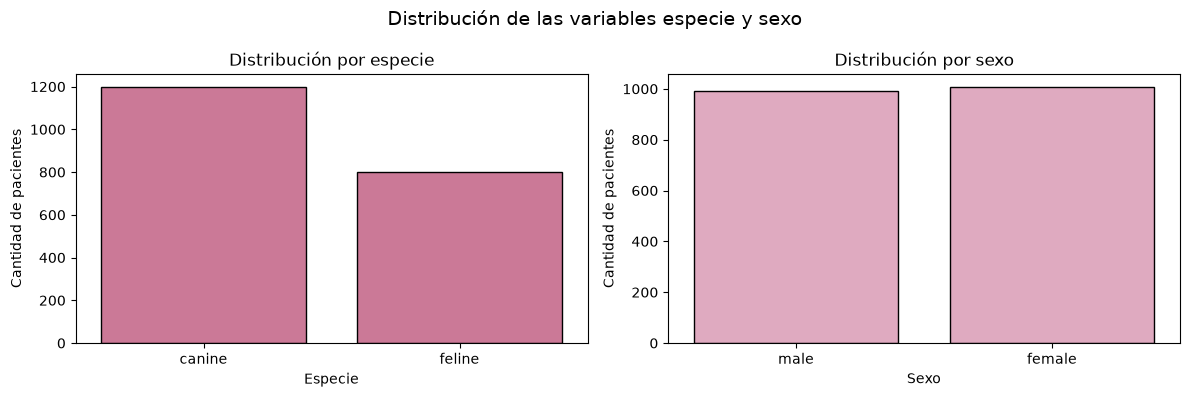

In [163]:
plot_categoricas_univariado(df)

Interpretacion: A partir de los gráficos de barras, se observa que el conjunto de datos presenta una mayor proporción de pacientes caninos (60 %) que felinos (40 %).
En cuanto al sexo, la distribución es relativamente equilibrada, con cantidades similares de machos y hembras.

### Frecuencia de las distintas razas

In [164]:

def plot_razas_univariado(df):
    '''
    Grafica la cantidad de pacientes por raza.
    '''

    plt.figure(figsize=(10, 6))

    sns.countplot(data=df, y='breed',
                  color='#d96b93', edgecolor='black')

    plt.title('Distribución de los pacientes según su raza')
    plt.xlabel('Cantidad de pacientes')
    plt.ylabel('Raza')

    plt.tight_layout()
    plt.show()


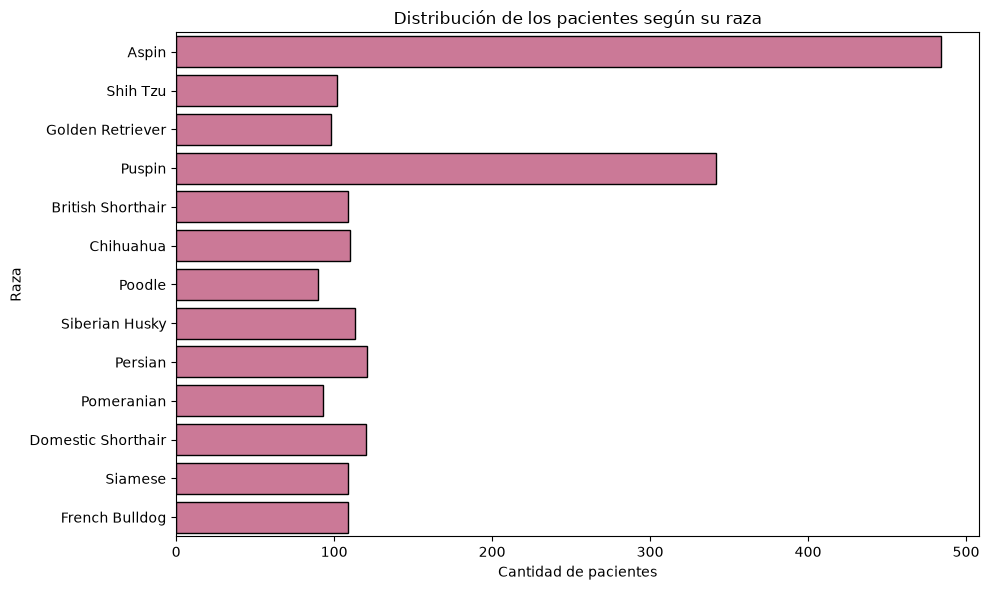

In [165]:
plot_razas_univariado(df)

Interpretacion: Se identifica que Aspin y Puspin son las categorías con mayor cantidad de pacientes, mientras que las demás razas presentan frecuencias relativamente similares y considerablemente menores.
Esto evidencia una distribución desigual de los pacientes según su raza, con una mayor representación de determinadas categorías dentro del dataset.

### Resultados de la lampara de Wood

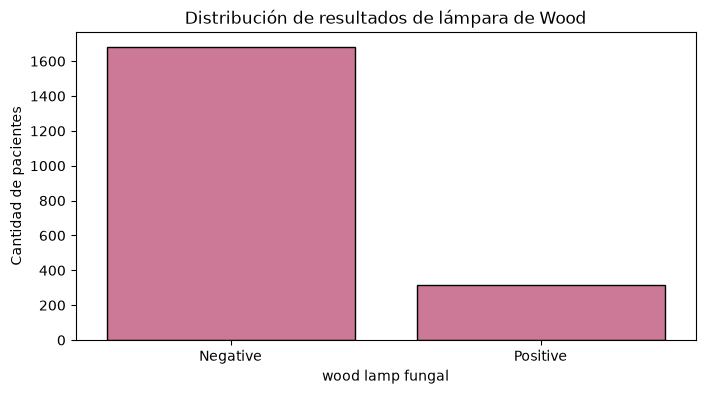

In [166]:

graficar_barras(df, 'wood lamp fungal',
                'Distribución de resultados de lámpara de Wood')


Interpretacion: El gráfico de barras muestra un claro predominio de resultados negativos en la prueba de lámpara de Wood, mientras que los resultados positivos representan una proporción considerablemente menor del conjunto de datos.
Esta distribución permite conocer la frecuencia de los resultados registrados. Sin embargo, un resultado negativo no implica necesariamente que el paciente esté sano o que no presente una enfermedad dermatológica.

## Analisis Bivariado

### Relacion entre peso y frecuencia cardiaca
Analizamos la relación entre el peso y la frecuencia cardíaca de los pacientes veterinarios mediante un gráfico de dispersión (scatterplot).
Además, diferenciaremos a los pacientes según su especie, con el objetivo de observar posibles patrones entre caninos y felinos.

In [167]:

def plot_scatter_peso_frecuencia(df):
    '''
    Grafica la relación entre peso y frecuencia cardíaca,
    diferenciando a los pacientes según su especie.
    '''

    plt.figure(figsize=(10, 5))

    sns.scatterplot(data=df, x='weight', y='heart rate',
                    hue='species',
                    palette={'canine': '#d96b93',
                             'feline': '#e8a1be'})

    plt.title('Relación entre peso y frecuencia cardíaca')
    plt.xlabel('Peso (kg)')
    plt.ylabel('Frecuencia cardíaca (lpm)')

    plt.tight_layout()
    plt.show()


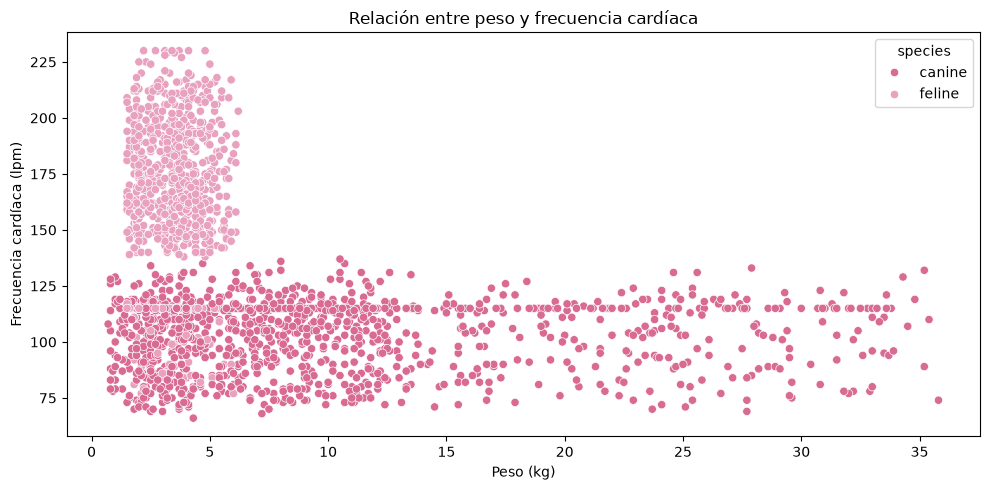

In [168]:
plot_scatter_peso_frecuencia(df)

Interpretación: Por un lado, los felinos presentan una distribución de peso más concentrada, principalmente entre los 2 y 6 kg. Sin embargo, sus frecuencias cardíacas se distribuyen en un intervalo relativamente amplio, aproximadamente entre 140 y 230 latidos por minuto (lpm).
Por otro lado, los caninos presentan una mayor variabilidad en su peso, con valores que van desde aproximadamente 1 kg hasta superar los 35 kg. En cambio, sus frecuencias cardíacas se concentran mayormente entre 70 y 135 lpm.
Estas observaciones permiten identificar que los felinos presentan, en general, frecuencias cardíacas más elevadas que los caninos, a pesar de tener pesos menores. Esto sugiere que la especie podría ser un factor importante al analizar la relación entre ambas variables.
A partir de estos resultados surge una nueva pregunta: ¿las diferencias observadas en la frecuencia cardíaca responden a características propias de cada especie o podrían estar relacionadas con el estado de salud de los pacientes?

### Relacion entre la frecuencia cardiaca y el estado de salud

In [169]:

def plot_variable_estado(df, columna, titulo, etiqueta_y):
    '''
    Compara una variable numérica entre animales sanos
    y enfermos, diferenciando caninos y felinos.
    '''

    # Seleccionamos los datos necesarios
    datos = df[['species', columna,
                'definitive diagnosis']].dropna().copy()

    # Clasificamos según el estado de salud
    datos['estado'] = datos['definitive diagnosis'].apply(
        lambda x: 'Sano' if x.strip().lower() == 'healthy'
        else 'Enfermo'
    )

    plt.figure(figsize=(12, 5))

    # Boxplot de caninos
    plt.subplot(1, 2, 1)
    sns.boxplot(data=datos[datos['species'] == 'canine'],
                x='estado', y=columna,
                order=['Sano', 'Enfermo'],
                color='#d96b93')

    plt.title('Caninos')
    plt.xlabel('Estado de salud')
    plt.ylabel(etiqueta_y)

    # Boxplot de felinos
    plt.subplot(1, 2, 2)
    sns.boxplot(data=datos[datos['species'] == 'feline'],
                x='estado', y=columna,
                order=['Sano', 'Enfermo'],
                color='#e8a1be')

    plt.title('Felinos')
    plt.xlabel('Estado de salud')
    plt.ylabel(etiqueta_y)

    plt.suptitle(titulo, fontsize=14)

    plt.tight_layout()
    plt.show()


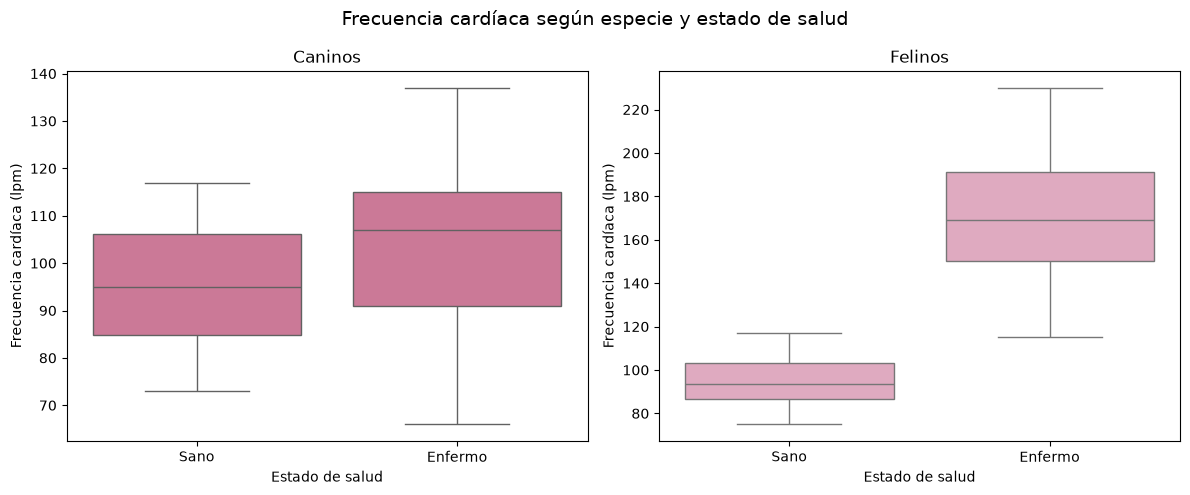

In [170]:
plot_variable_estado(
    df,
    'heart rate',
    'Frecuencia cardíaca según especie y estado de salud',
    'Frecuencia cardíaca (lpm)'
)

Interpretación: En los caninos, los pacientes enfermos presentan una mediana ligeramente superior a la de los sanos. Sin embargo, existe una superposición considerable entre ambas distribuciones, lo que sugiere que la frecuencia cardíaca, por sí sola, podría no ser suficiente para distinguir ambos grupos.
En los felinos, se observa una diferencia mucho más marcada. Los pacientes clasificados como enfermos presentan frecuencias cardíacas considerablemente superiores a las de los sanos, sin que se observe superposición entre los rangos representados en el gráfico.
Estos resultados sugieren que la relación entre frecuencia cardíaca y estado de salud podría variar según la especie, por lo que ambas variables podrían ser relevantes para el modelo predictivo.

### Relacion entre la temperatura corporal y el estado de salud 

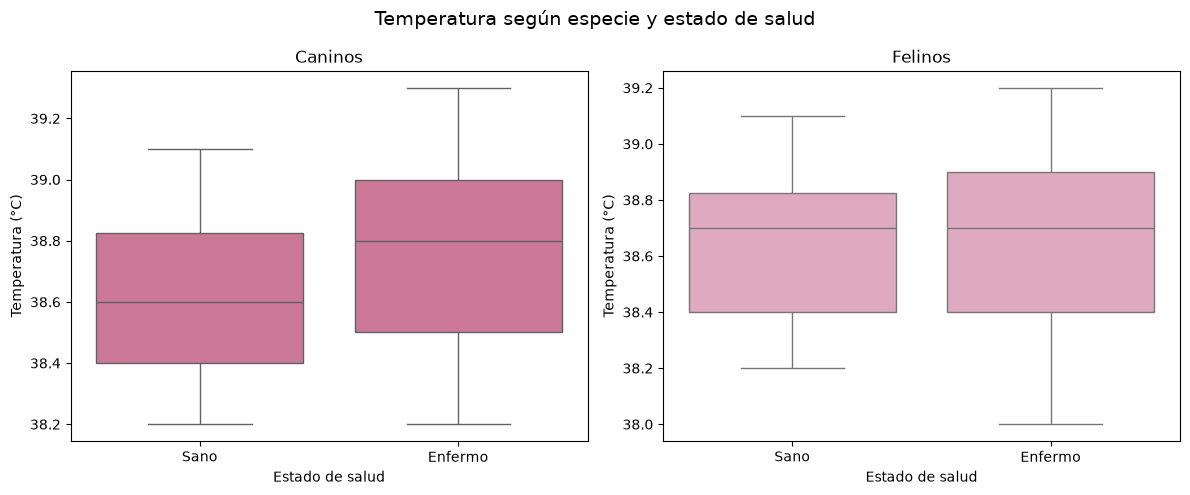

In [171]:
plot_variable_estado(
    df,
    'temperature',
    'Temperatura según especie y estado de salud',
    'Temperatura (°C)'
)

Interpretación: En los caninos, los pacientes enfermos presentan una mediana ligeramente superior a la de los sanos. Sin embargo, existe una superposición considerable entre ambas distribuciones.
En los felinos, las medianas de los pacientes sanos y enfermos son prácticamente iguales, y sus distribuciones también presentan un importante solapamiento.
Estos resultados sugieren que la temperatura corporal, considerada de manera aislada, podría tener una utilidad limitada para distinguir animales sanos y enfermos dentro del conjunto de datos.
A diferencia de lo observado con la frecuencia cardíaca, especialmente en los felinos, la temperatura no presenta diferencias visualmente marcadas entre los estados de salud. Sin embargo, esto no significa que deba descartarse como variable predictora, ya que podría aportar información al combinarse con otras características de los pacientes.

### Relacion entre edad y el estado de salud 

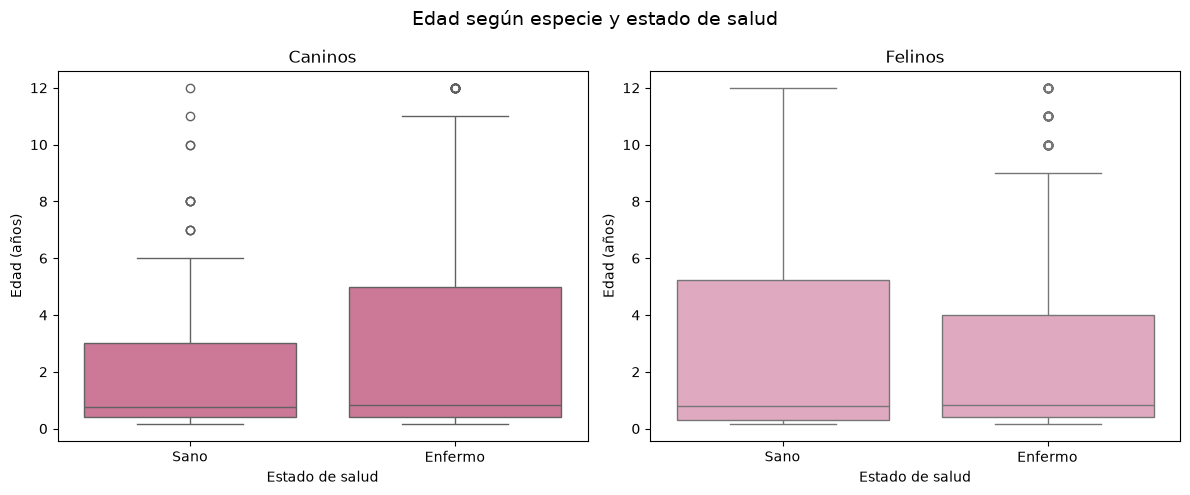

In [172]:
plot_variable_estado(
    df,
    'age',
    'Edad según especie y estado de salud',
    'Edad (años)'
)


Interpretacion: A partir de los boxplots, se observa que las medianas de edad de los pacientes sanos y enfermos son relativamente similares tanto en caninos como en felinos, aunque existen diferencias en la dispersión de sus distribuciones.
En los caninos, los pacientes enfermos presentan una mayor dispersión de edades dentro del 50 % central de las observaciones, mientras que los sanos muestran una distribución más concentrada en edades jóvenes. Además, se identifican posibles valores atípicos correspondientes a animales de mayor edad.
En los felinos, se observa una situación diferente: los pacientes sanos presentan una dispersión ligeramente mayor que los enfermos, aunque las medianas se mantienen próximas. También se identifican posibles valores atípicos en edades elevadas.
En ambos casos, las distribuciones presentan una superposición considerable, por lo que la edad, considerada de manera aislada, no parece permitir una diferenciación clara entre animales sanos y enfermos.

### Relación entre los resultados de la lámpara de Wood y el estado de salud

In [173]:
# Seleccionamos las columnas necesarias
datos_wood = df[['wood lamp fungal', 'definitive diagnosis']].dropna().copy()

# Clasificamos a los pacientes como sanos o enfermos
datos_wood['estado_salud'] = datos_wood['definitive diagnosis'].apply(
    lambda x: 'Sano' if x.strip().lower() == 'healthy'
    else 'Enfermo'
)


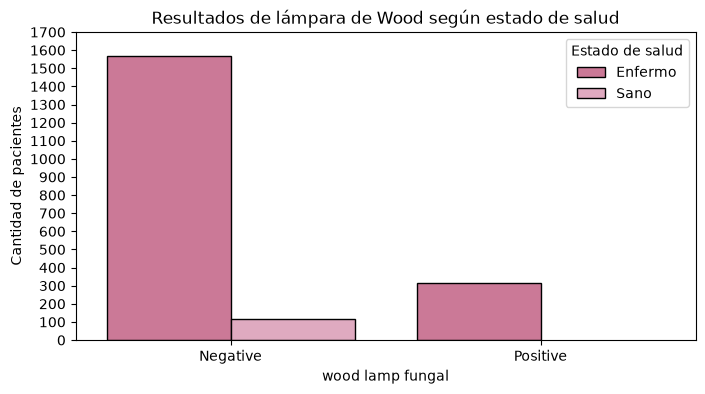

In [174]:
graficar_barras(
    datos_wood,
    'wood lamp fungal',
    'Resultados de lámpara de Wood según estado de salud',
    hue='estado_salud',
    paso_y=100,
    paleta={'Enfermo': '#d96b93', 'Sano': '#e8a1be'}
)


Interpretacion: Se identifica que todos los pacientes con resultado positivo aparecen clasificados como enfermos. Sin embargo, también se observa una cantidad considerable de animales enfermos entre aquellos que obtuvieron un resultado negativo.
Esto sugiere que un resultado positivo podría aportar información relevante para identificar determinados pacientes enfermos dentro del conjunto de datos, mientras que un resultado negativo no implica necesariamente que el animal esté sano.

### Relacion entre condición corporal según especie y estado de salud

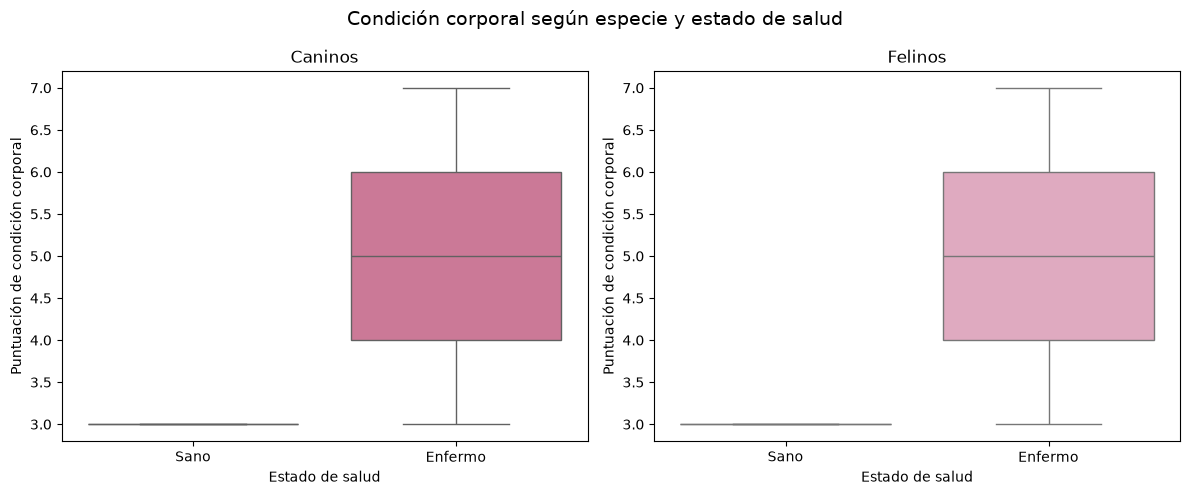

In [183]:

plot_variable_estado(
    df,
    'Body condition score',
    'Condición corporal según especie y estado de salud',
    'Puntuación de condición corporal'
)


Interpretacion: A partir de los boxplots, se observa una diferencia marcada en la distribución de las puntuaciones de condición corporal entre los pacientes sanos y enfermos.
Tanto en caninos como en felinos, los pacientes clasificados como sanos presentan una puntuación de condición corporal de 3, sin variabilidad visible.
En cambio, los pacientes enfermos presentan una mayor dispersión, con puntuaciones comprendidas entre 3 y 7 y una mediana cercana a 5 en ambas especies.
Estos resultados sugieren que la condición corporal podría aportar información relevante para distinguir el estado de salud de los pacientes. Sin embargo, una puntuación de 3 no garantiza que el animal esté sano, ya que también se registra entre los enfermos.

### Relación entre estado de salud y situcion de tenencia

In [177]:
# Seleccionamos las columnas necesarias
datos = df[['ownership_status', 'definitive diagnosis']].dropna().copy()

# Clasificamos a los pacientes como sanos o enfermos
datos['estado_salud'] = datos['definitive diagnosis'].apply(
    lambda x: 'Sano' if x.strip().lower() == 'healthy'
    else 'Enfermo'
)


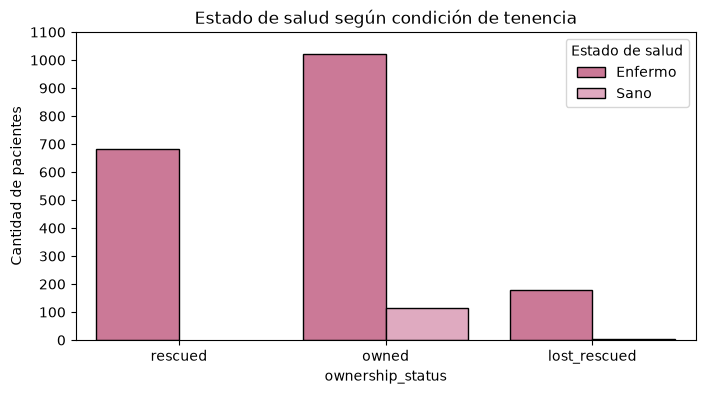

In [178]:
graficar_barras(
    datos,
    'ownership_status',
    'Estado de salud según condición de tenencia',
    hue='estado_salud',
    paso_y=100,
    paleta={'Enfermo': '#d96b93', 'Sano': '#e8a1be'}
)

Interpretación: El gráfico de barras agrupadas permite observar la distribución de pacientes sanos y enfermos según su condición de tenencia.
Se identifica un predominio de pacientes enfermos en las tres categorías, siendo especialmente marcada esta diferencia en los animales rescatados y en aquellos registrados como lost_rescued.
Estos resultados plantean la posibilidad de una asociación entre la condición de tenencia y el estado de salud. Sin embargo, será necesario comparar las proporciones de pacientes enfermos dentro de cada grupo y verificar la consistencia de los datos antes de establecer conclusiones definitivas.

### Análisis de correlación entre variables numéricas
Ahora calculamos la matriz de correlaciones de Pearson entre las principales variables numéricas del dataset: peso, temperatura, frecuencia cardíaca, edad y condición corporal.
Posteriormente, representamos los coeficientes mediante un mapa de calor (heatmap) para facilitar la identificación de posibles relaciones lineales entre estas características clínicas.

In [180]:

# Seleccionamos las variables numéricas relevantes
variables_numericas = [
    'age',
    'weight',
    'temperature',
    'heart rate',
    'Body condition score'
]

# Calculamos la matriz de correlaciones
corr_matrix = df[variables_numericas].corr()

corr_matrix


,age,weight,temperature,heart rate,Body condition score
age,1.000000,0.149847,-0.007351,0.012514,0.036794
weight,0.149847,1.000000,0.062153,-0.344999,0.008476
temperature,-0.007351,0.062153,1.000000,-0.107246,-0.006544
heart rate,0.012514,-0.344999,-0.107246,1.000000,0.084284
Body condition score,0.036794,0.008476,-0.006544,0.084284,1.000000


In [181]:

def plot_mapa_calor(corr_matrix):
    '''
    Grafica el mapa de calor de las correlaciones
    entre variables numéricas.
    '''

    plt.figure(figsize=(8, 6))

    sns.heatmap(corr_matrix, annot=True, cmap='RdPu',
                vmin=-1, vmax=1, fmt='.2f')

    plt.title('Mapa de calor de correlaciones')

    plt.tight_layout()
    plt.show()


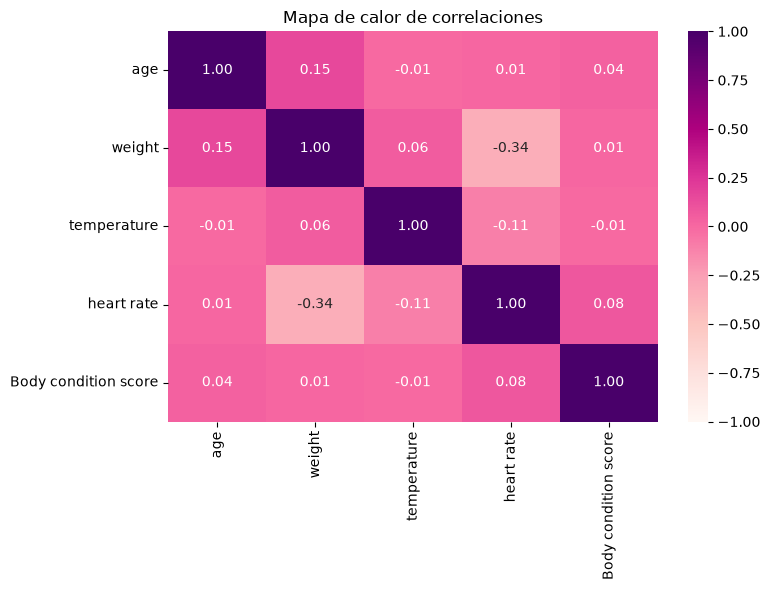

In [182]:
plot_mapa_calor(corr_matrix)

Interpretacion: A partir de la matriz de correlaciones de Pearson, se observa que la mayoría de las variables numéricas presentan asociaciones lineales muy débiles o prácticamente nulas.
La relación más destacada corresponde al peso y la frecuencia cardíaca, con un coeficiente aproximado de −0,345, lo que indica una correlación negativa débil. Esto sugiere que, dentro del conjunto de datos, los pacientes de mayor peso tienden a presentar frecuencias cardíacas menores.
Sin embargo, esta relación podría estar influida por las diferencias entre especies, ya que anteriormente observamos que los felinos presentan, en general, pesos menores y frecuencias cardíacas superiores a las de los caninos.
Por otro lado, la edad presenta correlaciones muy bajas con las demás variables numéricas. Su asociación más elevada corresponde al peso (r ≈ 0,15), mientras que con la temperatura, la frecuencia cardíaca y la condición corporal los coeficientes son cercanos a cero.
En general, no se identifican correlaciones lineales fuertes entre las características numéricas analizadas.

## Agrupaciones y Visualizaciones:
En esta sección analizaremos los datos agrupados por especie y sexo, estudiaremos los diagnósticos más frecuentes y evaluaremos la viabilidad de una serie temporal.

In [ ]:
#agrupacion de datos cruzando las columnas "definitive diagnosis", "species" y "sex"
resumen_cruzado = df.groupby(["definitive diagnosis", "species", "sex"]).agg(
    total_casos=('Patient ID', 'count'),
    peso_promedio=('weight', 'mean'),
    temp_promedio=('temperature', 'mean'),
    bcs_promedio=('Body condition score', 'mean')
).reset_index()

# Mostramos el resultado ordenado por los que tienen más casos
display(resumen_cruzado.sort_values(by='total_casos', ascending=False).head(10))

KeyError: "Label(s) ['Patient ID'] do not exist"

### Gráfico de distribución de diagnósticos
A continuación, visualizamos la frecuencia de los diagnósticos definitivos comparados entre especies para detectar patrones relevantes:

<Figure size 1100x600 with 0 Axes>

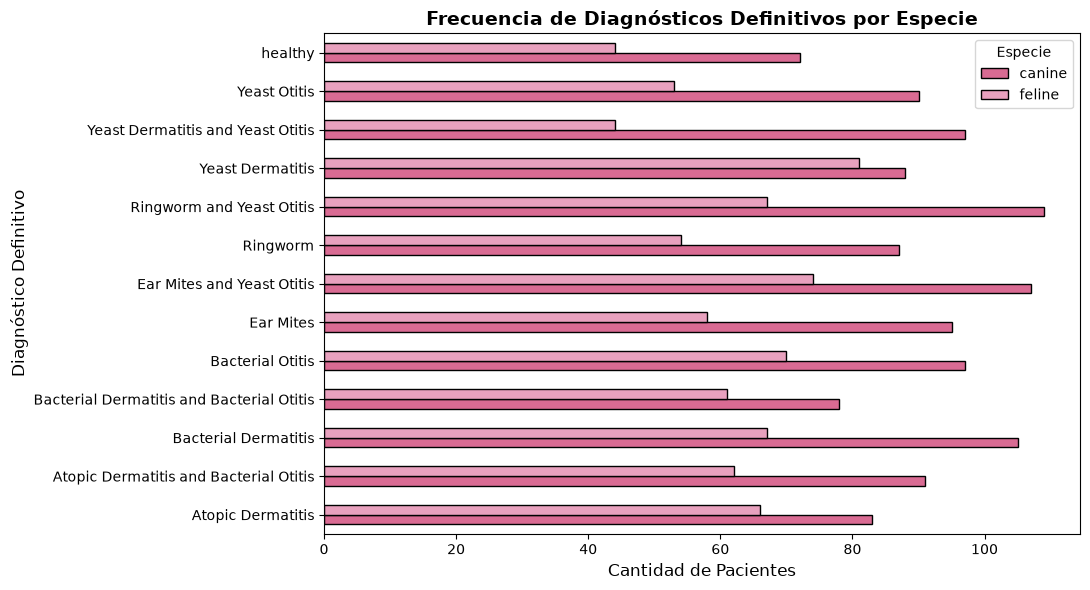

In [ ]:
import matplotlib.pyplot as plt
#Tabla cruzada de diagnósticos definitivos según la especie
diag_especie = pd.crosstab(df['definitive diagnosis'], df['species'])

#grafico de barras apiladas para visualizar la distribución de diagnósticos por especie
plt.figure(figsize=(11, 6))
diag_especie.plot(kind='barh', figsize=(11, 6), color=['#d96b93', '#e8a1be'], edgecolor='black')
plt.title('Frecuencia de Diagnósticos Definitivos por Especie', fontsize=14, fontweight='bold')
plt.xlabel('Cantidad de Pacientes', fontsize=12)
plt.ylabel('Diagnóstico Definitivo', fontsize=12)
plt.legend(title='Especie')
plt.tight_layout()
plt.show()

### Interpretación de Hallazgos y Análisis Temporal

* **Diagnósticos más frecuentes:** Los motivos de consulta más repetidos en la veterinaria son *Ear Mites and Yeast Otitis* (181 casos), *Ringworm and Yeast Otitis* (176 casos) y *Bacterial Dermatitis* (172 casos).
* **Diferencias entre grupos:** Los caninos concentran mayor volumen de casos totales (destacando en infecciones fúngicas y de ácaros), mientras que los felinos muestran una alta incidencia en *Yeast Dermatitis*.

#### Justificación sobre la Serie Temporal:
* **¿Es posible armar una serie temporal?** No. 
* **Motivo:** Las columnas de fecha (`intake date` y `booking date`) poseen una gran cantidad de valores faltantes (más de 800 y 1100 nulos respectivamente). Al unificarlas, todavía queda un porcentaje importante de registros sin fecha alguna, y la distribución temporal está fragmentada entre 2023, 2024 y 2025 sin una continuidad uniforme. Forzar una serie temporal introduciría sesgos graves, por lo que se decide descartar este enfoque analítico y focalizar el modelo predictivo en las características clínicas del paciente.